Author: Enikő Gergely <br>
Date: October 2026
    
# Back-Gluteal Angle vs OBP Analysis with automated data collection

The goal is to analyze further the relationship between the Back-Gluteal angle and the batting performance in general. This notebook analyzes the relationship between player's batting posture during their batting stance and their offensive performance in 2025. Using video frames from Baseball Savant, I track their body posture by measuring the Back-Gluteal angle and compare it with their batting statistics, OBP.

This notebook analyzes the output of the automated data collection process and includes outlier removal, average angle and OBP comparison for qualified players (>500 PA) to identify any relationship between posture and performance. 

There are several stadiums where the fans are visible behind the batter that sometimes mislead the silhouette function and lead to incorrect Back-Gluteal Angles. For a more precised analysis these cases should be removed. This notebook intends to show a high level relationship. 

The preprocessing notebook includes automated image processing, finding player silhouette and angle measurements:
- 2025 Analysis - Data Collection


# Import Packages

In [36]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import math

# Load Data
Load the output file from the automated data collection process.

 #### Angle Data

In [10]:
df = pd.read_excel('All_player_results.xlsx')



#### Player statistics data

In [11]:
df_player_list = pd.read_csv('stats_with_team.csv')
df_player_list.head()

,Unnamed: 0,"last_name, first_name",player_id,year,pa,k_percent,bb_percent,slg_percent,on_base_percent,on_base_plus_slg,...,sweet_spot_percent,barrel_batted_rate,hard_hit_percent,avg_best_speed,avg_hyper_speed,whiff_percent,swing_percent,team_id,team_name,team_abbreviation
0,0,"Torres, Gleyber",650402,2025,628,16.1,13.5,0.387,0.358,0.745,...,38.6,8.2,39.0,99.951682,94.284675,19.5,40.8,116,Detroit Tigers,DET
1,1,"Contreras, William",661388,2025,659,18.2,12.7,0.399,0.355,0.754,...,31.6,6.4,48.5,102.570622,95.839705,24.2,46.5,158,Milwaukee Brewers,MIL
2,2,"Cronenworth, Jake",630105,2025,515,20.8,13.4,0.377,0.367,0.744,...,31.9,6.2,39.0,99.154485,93.790990,18.8,42.7,135,San Diego Padres,SD
3,3,"Walker, Christian",572233,2025,640,27.7,6.3,0.421,0.297,0.718,...,34.5,12.9,46.1,102.499786,95.668558,30.5,52.2,117,Houston Astros,HOU
4,4,"McCutchen, Andrew",457705,2025,551,21.4,12.2,0.367,0.333,0.700,...,34.5,8.4,42.5,100.124243,94.328515,26.2,45.6,134,Pittsburgh Pirates,PIT


In [12]:
df_player_list.columns

Index(['Unnamed: 0', 'last_name, first_name', 'player_id', 'year', 'pa',
       'k_percent', 'bb_percent', 'slg_percent', 'on_base_percent',
       'on_base_plus_slg', 'woba', 'xwoba', 'sweet_spot_percent',
       'barrel_batted_rate', 'hard_hit_percent', 'avg_best_speed',
       'avg_hyper_speed', 'whiff_percent', 'swing_percent', 'team_id',
       'team_name', 'team_abbreviation'],
      dtype='object')

# Remove outliers:
Since some images have imperfect silhouette due to low image quality, or in some cases due to fans in the background, I remove outliers to improve the data quality.


In [13]:
def remove_outliers(group):
    Q1 = group['angle'].quantile(0.25)
    Q3 = group['angle'].quantile(0.75)
    IQR = Q3 - Q1
    
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    return group[
        (group['angle'] >= lower) &
        (group['angle'] <= upper)
    ]


print("Before Outlier Removal: ", len(df))

df_clean = (
    df.groupby('player_id', group_keys=False)
      .apply(remove_outliers)
      .reset_index(drop=True)
)

print("After Outlier Removal: ", len(df_clean))
print("Number of items removed: ", len(df) - len (df_clean))

Before Outlier Removal:  933
After Outlier Removal:  881
Number of items removed:  52


C:\Users\eniko\AppData\Local\Temp\ipykernel_26228\1028945132.py:19: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(remove_outliers)


### Mean Angle Calculation
Here I calculate the mean angle by player for 2025 and add their 2025 OBP to the dataframe.

In [14]:
mean_anlge_by_player = df_clean.groupby(['player_id', 'player_name'])[['angle']].mean().reset_index()

data = mean_anlge_by_player.merge(df_player_list[['player_id', 'on_base_percent']], on = 'player_id', how= 'left')
data

,player_id,player_name,angle,on_base_percent
0,457705,"McCutchen, Andrew",97.008025,0.333
1,502671,"Goldschmidt, Paul",99.316949,0.328
2,518692,"Freeman, Freddie",102.330979,0.367
3,521692,"Perez, Salvador",102.750025,0.284
4,542303,"Ozuna, Marcell",108.989170,0.355
...,...,...,...,...
59,691406,"Caminero, Junior",98.722401,0.311
60,694192,"Chourio, Jackson",102.965923,0.308
61,696100,"Goodman, Hunter",104.289760,0.323
62,805367,"Meidroth, Chase",96.539471,0.329


# Visuals

I create a scatterplot to see if there is a relationship between OBP and player's back angle.

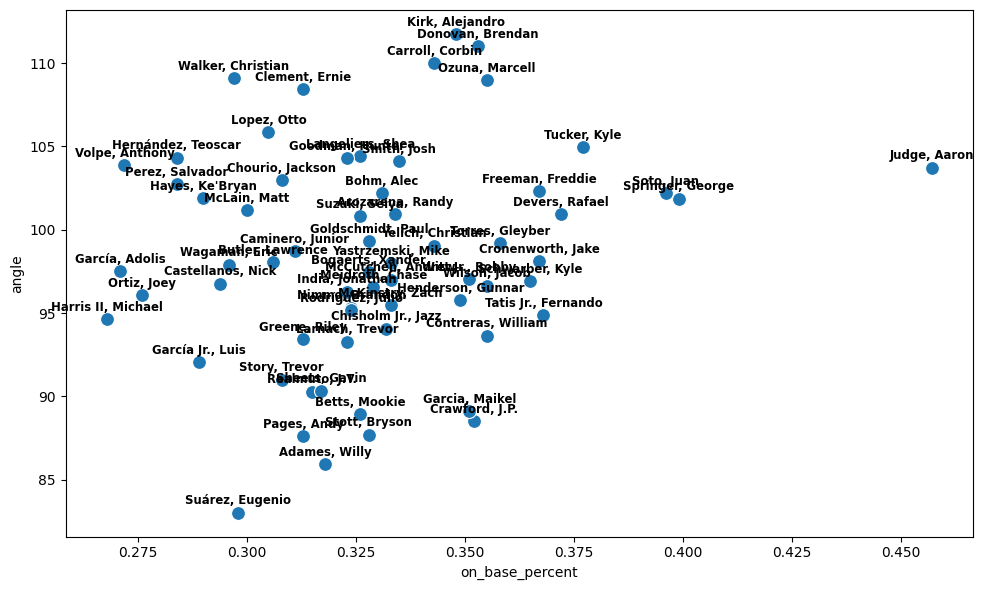

In [15]:
plt.figure(figsize=(10, 6))

# scatterplot:
ax = sns.scatterplot(data=data, x='on_base_percent', y='angle', s = 100) #, hue = 'player_name', s = 100)

# Add player names to the scatterplot
for i in range(data.shape[0]):
    ax.text(
        x=data['on_base_percent'].iloc[i], 
        y=data['angle'].iloc[i] + 0.5,
        s=data['player_name'].iloc[i],
        horizontalalignment='center',
        size='small', 
        color='black', 
        weight='semibold'
    )


#plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

There seems to be no clear relationship between angle and OBP. As seen earlier with Christian Yelich, angle data can give more information on individual player's health and can be in a relationship with OBP but in general it is not the case. Player's should be analyzed case by case.


### Filtered results by stadiums
There are several stadiums where the fans are visible behind the batter that often mislead the silhouette function and lead to incorrect Back-Gluteal Angles. Here I collected the Stadiums where the Back-Gluteal line seems to be correct and fans are not visible in the background, and filtered the data only for those Stadiums.

In [17]:
# list of stadiums:
df_clean['team'].unique()

array(['PIT', 'NYY', 'LAD', 'KC', 'ATL', 'TOR', 'AZ', 'HOU', 'SF', 'PHI',
       'MIL', 'SD', 'BOS', 'NYM', 'SEA', 'DET', 'MIN', 'CHC', 'TEX',
       'ATH', 'WSH', 'MIA', 'CIN', 'STL', 'BAL', 'TB', 'COL', 'CWS'],
      dtype=object)

In [18]:
# group stadiums
clear_background_stadium_list = ['ATH', 'BAL', 'BOS', 'CHC', 'CIN', 'COL', 'CWS', 'DET', 'HOU',
                                'LAD', 'MIL','MIN','NYM', 'NYY', 'PHI', 'PIT', 'SEA', 'TB', 'TEX','TOR' ]

teams_to_filter_out = ['AZ', 'KC', 'MIA',  'SD', 'SF', 'STL', 'WSH']

In [31]:
# filter the data for good stadiums only:
df_clean_filtered_stadiums = df_clean[df_clean['team'].isin(clear_background_stadium_list)]

mean_anlge_by_player_filtered_stadiums = df_clean_filtered_stadiums.groupby(['player_id', 'player_name', 'team'])[['angle']].mean().reset_index()

data_filtered_stadiums = mean_anlge_by_player_filtered_stadiums.merge(df_player_list[['player_id', 'on_base_percent']], on = 'player_id', how= 'left')
print(len(data_filtered_stadiums))

46


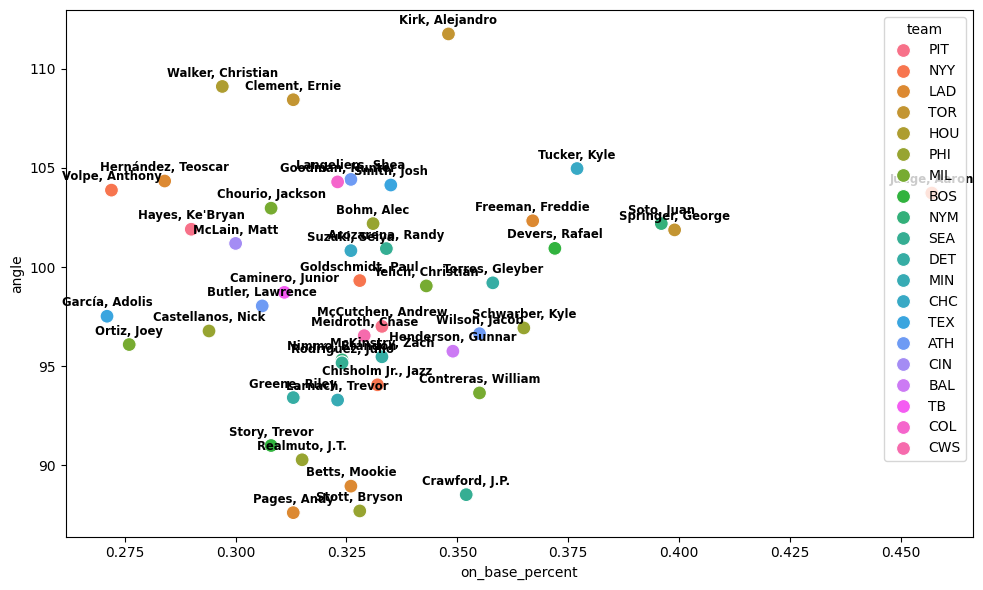

In [20]:
# plot good stadiums only:
plt.figure(figsize=(10, 6))

# scatterplot:
ax = sns.scatterplot(data=data_filtered_stadiums, x='on_base_percent', y='angle', s = 100, hue = 'team') #, hue = 'player_name', s = 100)

# Add player names to the scatterplot
for i in range(data_filtered_stadiums.shape[0]):
    ax.text(
        x=data_filtered_stadiums['on_base_percent'].iloc[i], 
        y=data_filtered_stadiums['angle'].iloc[i] + 0.5,     
        s=data_filtered_stadiums['player_name'].iloc[i], 
        horizontalalignment='center',  
        size='small', 
        color='black', 
        weight='semibold'
    )


#plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Filtered results by player 
I manually collected some players with perfect Back-Gluteal lines and here I create a scatterplot for those players only.

In [33]:
# players with perfect silhouettes and angles:
player_ids_with_perfect_lines = [
        669127,
        671739,
        542303,
        646240,
        663656,
        680574,
        805367,
        682985,
        656716,
        572233,
        521692,
        518692,
        606192,
        672640,
        687401,
        592885,
        665742,
        592450,
        683011,
        663647,
        666969,
        669701,
        672386,
        543807 ]

data_with_perfect_lines = data[data['player_id'].isin(player_ids_with_perfect_lines)]

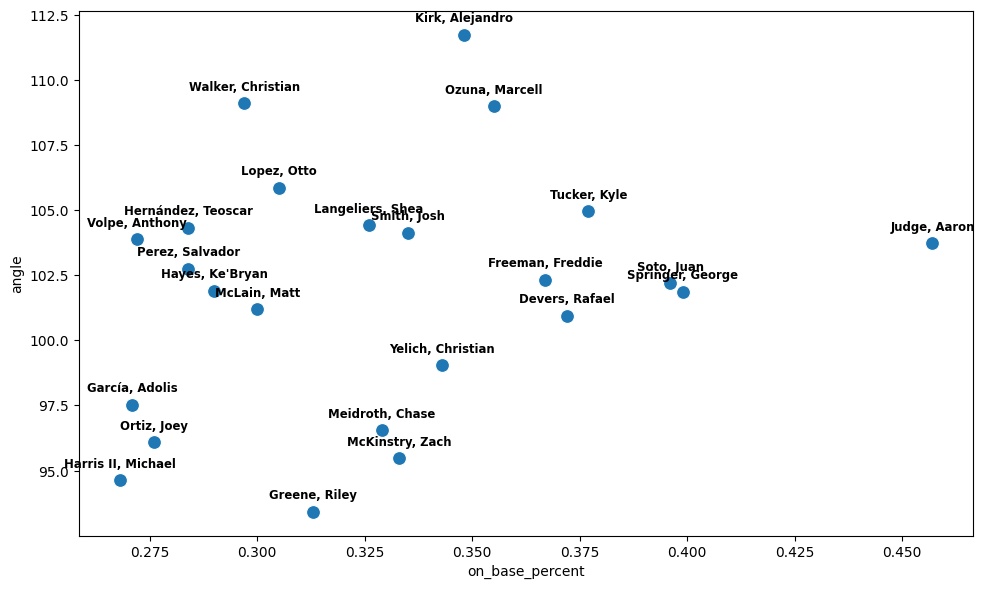

In [34]:
# plot only players with perfect angles:
plt.figure(figsize=(10, 6))

# scatterplot:
ax = sns.scatterplot(data=data_with_perfect_lines, x='on_base_percent', y='angle', s = 100) #, hue = 'player_name', s = 100)

# Add player names to the scatterplot
for i in range(data_with_perfect_lines.shape[0]):
    ax.text(
        x=data_with_perfect_lines['on_base_percent'].iloc[i], 
        y=data_with_perfect_lines['angle'].iloc[i] + 0.5,
        s=data_with_perfect_lines['player_name'].iloc[i],
        horizontalalignment='center',
        size='small', 
        color='black', 
        weight='semibold'
    )


#plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

It still does not show a clear relationship between the Back-Gluteal angle and OBP.

## Average Angles by player - ascending
Here I list all the analyzed player and their average angle data in ascending order. (Switch hitters has been removed from the final angle calculations thus showing only 64 hitters). 

In [41]:
pd.set_option('display.max_rows', None)
data.sort_values(by = 'angle', ascending = True)

,player_id,player_name,angle,on_base_percent
6,553993,"Suárez, Eugenio",83.028759,0.298
20,642715,"Adames, Willy",85.954471,0.318
53,681624,"Pages, Andy",87.618182,0.313
52,681082,"Stott, Bryson",87.704748,0.328
19,641487,"Crawford, J.P.",88.525299,0.352
15,605141,"Betts, Mookie",88.954522,0.326
43,672580,"Garcia, Maikel",89.123478,0.351
11,592663,"Realmuto, J.T.",90.283572,0.315
25,657757,"Sheets, Gavin",90.349503,0.317
14,596115,"Story, Trevor",91.002269,0.308
